# Chapter 1

Python version of the R code for Chapter 1 of *In All Likelihood* (Pawitan, 2001).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from helpers import DATA

## Example 1.1 (`EX1-1.R`)

Planetary distances.

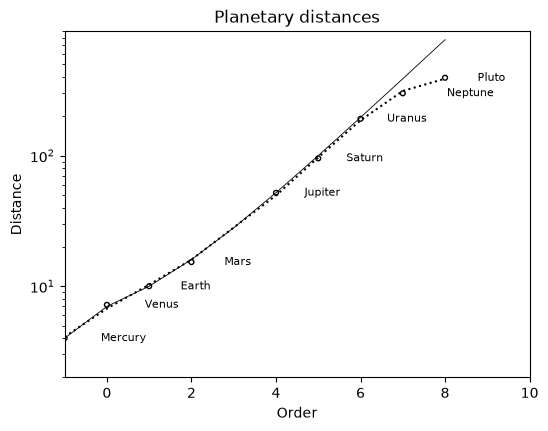

In [2]:
# planet.dat: skip the 5 header lines (the last of which is the sun)
rows = [line.split() for line in (DATA / "planet.dat").read_text().splitlines()[5:]
        if line.strip()]
names = [r[0] for r in rows]
dist = np.array([float(r[1]) for r in rows])
diam = np.array([float(r[2]) for r in rows])
mass = np.array([float(r[3]) for r in rows])
rota = np.array([float(r[4]) for r in rows])
revo = np.array([float(r[5]) for r in rows])
moon = np.array([float(r[6]) for r in rows])

dist = np.round(dist / dist[2] * 10, 1)  # Earth = 10
order = np.arange(0, 9)
theory = np.concatenate([[4], 4 + 3 * 2.0 ** order])

xpos = np.array([-1, 0, 1, 2, 4, 5, 6, 7, 8])
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(xpos, dist, s=12, facecolors="none", edgecolors="k")
off = 1.1 + np.array([.3, .2, 0, 0, 0, 0, 0, .5, 0])
for xi, di, name in zip(xpos + off, dist, names):
    ax.text(xi, di, name, fontsize=8, ha="center", va="center")
ax.plot(np.arange(-1, 9), theory, "k-", lw=0.6)

# 4th-degree polynomial fit of log(distance) on order
ord_ = np.array([0, 1, 2, 3, 5, 6, 7, 8, 9])
coef = np.polyfit(ord_, np.log(dist), 4)
ax.plot(xpos, np.exp(np.polyval(coef, ord_)), "k:")

ax.set_yscale("log")
ax.set_xlim(-1, 10)
ax.set_ylim(2, 900)
ax.set_xlabel("Order")
ax.set_ylabel("Distance")
ax.set_title("Planetary distances")
plt.show()